In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [2]:
wavelet_results_2_5 = pd.read_csv("../results/v2.1/v2.5/wavelet_results.csv")
wavelet_results_2_5_1 = pd.read_csv("../results/v2.5_seed_51/wavelet_results.csv")

In [3]:
all_results = pd.concat([wavelet_results_2_5, wavelet_results_2_5_1])

In [ ]:
resumo = (
    all_results.groupby(["dataset", "wavelet_family"])
      .agg(eer_mean=("eer", "mean"),
           eer_std=("eer", "std"),
           auc_mean=("roc_auc", "mean"),
           f1_mean=("f1_macro", "mean"))
      .mul(100)
      .reset_index()
      .sort_values(["dataset", "eer_mean"])
)

resumo["rank"] = resumo.groupby("dataset").cumcount() + 1
resumo["EER (%)"] = resumo.apply(
    lambda r: f"{r.eer_mean:.2f} ± {r.eer_std:.2f}", axis=1
)

for ds, t in resumo.groupby("dataset"):
    print(f"\n{ds}")
    print(t[["rank", "wavelet_family", "EER (%)", "auc_mean", "f1_mean"]]
          .round(2).to_string(index=False))


ASVspoof 2019
 rank wavelet_family     EER (%)  auc_mean  f1_mean
    1            db4 5.98 ± 0.09     98.64    86.51
    2           db28 6.04 ± 0.29     98.45    86.41
    3            db6 6.54 ± 0.76     98.38    85.46
    4           db26 6.57 ± 1.06     98.20    85.44
    5           db24 6.57 ± 0.47     98.31    85.41
    6           db14 6.75 ± 1.01     98.26    85.09
    7           db34 6.77 ± 0.08     98.12    85.04
    8           db18 6.98 ± 1.26     98.09    84.70
    9           db38 7.17 ± 0.45     98.07    84.33
   10           db16 7.21 ± 0.65     97.99    84.25
   11            db8 7.39 ± 1.80     97.90    84.01
   12           db36 7.88 ± 0.61     97.64    83.09

ASVspoof 2021
 rank wavelet_family      EER (%)  auc_mean  f1_mean
    1           db14 14.43 ± 0.92     91.71    73.03
    2           db18 14.68 ± 0.38     90.84    72.70
    3           db38 14.76 ± 0.68     91.18    72.60
    4           db24 14.80 ± 0.82     91.17    72.56
    5            db4 15.08 ± 

In [7]:
db_4_training_1 = pd.read_csv("../results/v2.1/v2.5/training_db4.csv")
db_4_training_2 = pd.read_csv("../results/v2.5_seed_51/training_db4.csv")

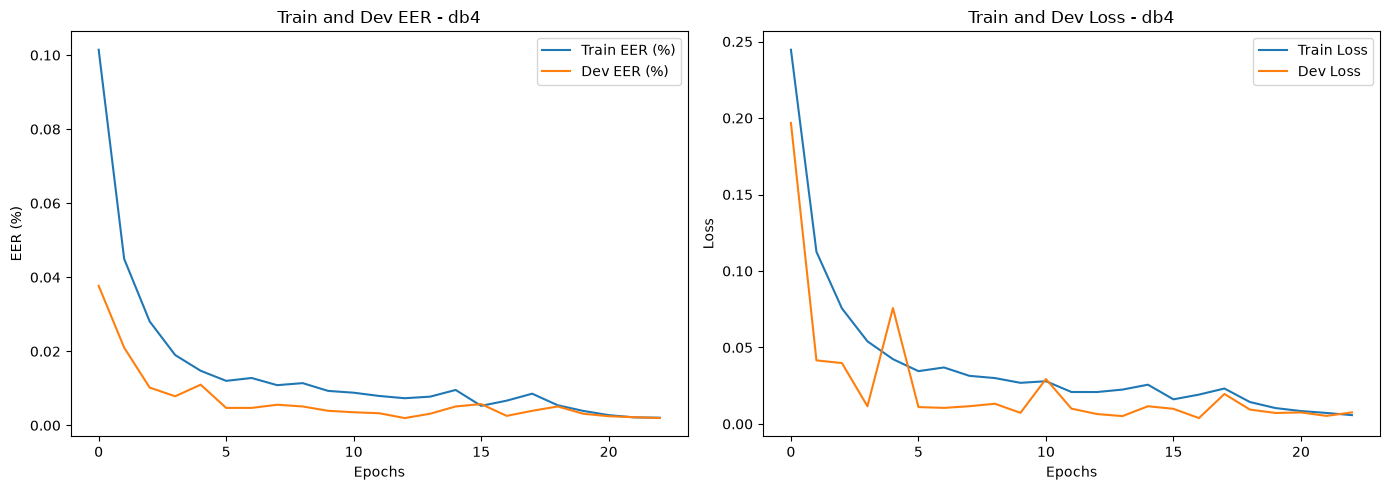

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(db_4_training_1["train_eer"], label="Train EER (%)")
axes[0].plot(db_4_training_1["dev_eer"], label="Dev EER (%)")
axes[0].set_title("Train and Dev EER - db4")
axes[0].set_ylabel("EER (%)")
axes[0].set_xlabel("Epochs")
axes[0].legend()

axes[1].plot(db_4_training_1["train_loss"], label="Train Loss")
axes[1].plot(db_4_training_1["dev_loss"], label="Dev Loss")
axes[1].set_title("Train and Dev Loss - db4")
axes[1].set_ylabel("Loss")
axes[1].set_xlabel("Epochs")
axes[1].legend()

fig.tight_layout()
plt.show()

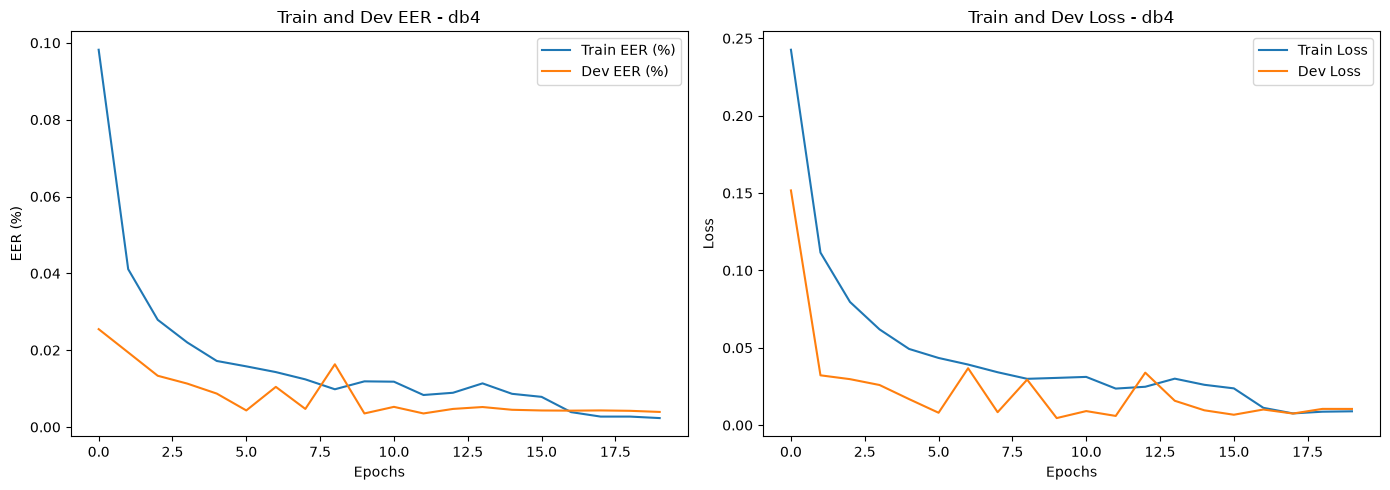

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(db_4_training_2["train_eer"], label="Train EER (%)")
axes[0].plot(db_4_training_2["dev_eer"], label="Dev EER (%)")
axes[0].set_title("Train and Dev EER - db4")
axes[0].set_ylabel("EER (%)")
axes[0].set_xlabel("Epochs")
axes[0].legend()

axes[1].plot(db_4_training_2["train_loss"], label="Train Loss")
axes[1].plot(db_4_training_2["dev_loss"], label="Dev Loss")
axes[1].set_title("Train and Dev Loss - db4")
axes[1].set_ylabel("Loss")
axes[1].set_xlabel("Epochs")
axes[1].legend()

fig.tight_layout()
plt.show()